# Course 13: Machine Learning for Agriculture and Climate
## Session 11: Sensors, soil and water on the farm

**Goal:** simulate a soil-moisture sensor with noise, spikes, gaps and drift, clean it with a moving average and a Kalman filter, detect spikes and drift, and compare irrigation decisions made from raw and cleaned readings by water used and days of crop stress.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. A field, a water balance and a cheap sensor
A soil-moisture sensor reports the **volumetric water content** $\theta$, the fraction of the soil volume that is water. The crop takes water from a root zone, here 0.3 m deep. Following FAO-56 (Allen et al. 1998), water between **field capacity** ($\theta_{fc} = 0.32$, what the soil holds after draining) and the **wilting point** ($\theta_{wp} = 0.12$) is available to the crop:

* total available water $\text{TAW} = 1000\,(\theta_{fc} - \theta_{wp})\,Z_r = 60$ mm for $Z_r = 0.3$ m;
* readily available water $\text{RAW} = p\,\text{TAW} = 30$ mm with $p = 0.5$; once more than RAW is used, the crop is **stressed** and transpires less, by the factor $K_s = (\text{TAW} - D_r)/((1 - p)\,\text{TAW})$, where $D_r$ is the depletion;
* so stress starts below $\theta = 0.32 - 30/300 = 0.22$.

Each hour the soil gains rain and irrigation and loses evapotranspiration (ET); water above field capacity drains away. We simulate 120 days of a dry season, hour by hour. The farmer's rule: every morning at 6:00, if the estimated $\theta$ is below 0.24, irrigate 35 mm.

**The sensor is synthetic, with four faults** that real low-cost sensors show: noise (standard deviation 0.015), spikes on 1% of readings, missing readings (two outages of several days plus 3% random losses) and a slow **drift** that starts on day 60 and makes it read 0.0015 wetter every day. Real data would come from your own sensor network (section 6).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

t_start = time.time()
np.random.seed(0)
rng = np.random.default_rng(0)

DAYS, H = 120, 24
N = DAYS * H
ZR, FC, WP, P = 0.3, 0.32, 0.12, 0.5
TAW = 1000 * (FC - WP) * ZR                     # 60 mm
RAW = P * TAW                                   # 30 mm
TH_STRESS = FC - RAW / (1000 * ZR)              # 0.22: below this the crop is stressed
TRIGGER, DOSE = 0.24, 35.0                      # irrigate 35 mm when the estimate is below 0.24
hour, day = np.arange(N) % H, np.arange(N) // H

et0_day = 4.0 + 1.0 * np.sin(2 * np.pi * np.arange(DAYS) / DAYS) + rng.normal(0, 0.4, DAYS)   # reference ET (mm/day)
et0 = np.where((hour >= 6) & (hour < 18), et0_day[day] / 12, 0.0)                              # spread over daylight hours
et0_station = et0 * np.repeat(rng.normal(1.0, 0.1, DAYS), H)       # what the farm's weather station estimates (10% error)
rain = np.zeros(N)
for d in np.nonzero(rng.random(DAYS) < 0.08)[0]:                   # a few showers in the dry season
    rain[d * H + rng.integers(12, 20)] = rng.gamma(1.5, 8)

noise = rng.normal(0, 0.015, N)
spike = rng.random(N) < 0.01
spikes = np.where(spike, rng.choice([-1, 1], N) * rng.uniform(0.08, 0.2, N), 0.0)
missing = rng.random(N) < 0.03
missing[(day >= 35) & (day < 38)] = True                           # a 3-day outage (battery)
missing[(day >= 90) & (day < 92)] = True                           # a 2-day outage (radio link)
DRIFT_START, DRIFT_RATE = 60, 0.0015
drift = np.where(day >= DRIFT_START, DRIFT_RATE * (np.arange(N) / H - DRIFT_START), 0.0)

def stress_factor(theta):
    dr = 1000 * ZR * (FC - theta)                                  # depletion of the root zone (mm)
    return 1.0 if dr <= RAW else max(0.0, (TAW - dr) / ((1 - P) * TAW))

print(f"TAW {TAW:.0f} mm, RAW {RAW:.0f} mm, stress below theta = {TH_STRESS:.2f}; total ET0 {et0.sum():.0f} mm, rain {rain.sum():.0f} mm on {int((rain > 0).sum())} days")
print(f"sensor faults: {spike.sum()} spikes, {missing.sum()} missing hours ({missing.mean():.1%}), drift from day {DRIFT_START} "
      f"reaching {drift.max():+.3f} by day {DAYS}")

TAW 60 mm, RAW 30 mm, stress below theta = 0.22; total ET0 484 mm, rain 76 mm on 8 days
sensor faults: 27 spikes, 214 missing hours (7.4%), drift from day 60 reaching +0.090 by day 120


### 2. One season, and three ways to estimate the true moisture
First we run one season in which the farmer irrigates from the **true** moisture, and look only at days 0–59, before the drift. Three estimates, each using only readings up to the current hour (as a real controller must):

* the **latest reading** (missing hours keep the previous reading);
* a **12-hour moving average** of the readings available;
* a **Kalman filter** (Kalman 1960). It keeps an estimate $\hat\theta$ and its variance $P$. Each hour it **predicts** with the water balance, using the measured rain, the logged irrigation and the station's ET, and adds process variance $Q$ for what the balance gets wrong. When a reading $z$ arrives it **updates**: $\hat\theta \leftarrow \hat\theta + K(z - \hat\theta)$ with gain $K = P/(P + R)$, where $R$ is the sensor's noise variance. A reading more than 4 standard deviations from the prediction is rejected as a probable spike. During an outage it simply keeps predicting.

latest reading          RMSE days 0-59: 0.0229  | during the 3-day outage: 0.0479
12-hour moving average  RMSE days 0-59: 0.0179  | during the 3-day outage: 0.0486
Kalman filter           RMSE days 0-59: 0.0047  | during the 3-day outage: 0.0021
spikes rejected by the Kalman filter's 4-sigma gate: 13 of 13; good readings rejected: 0


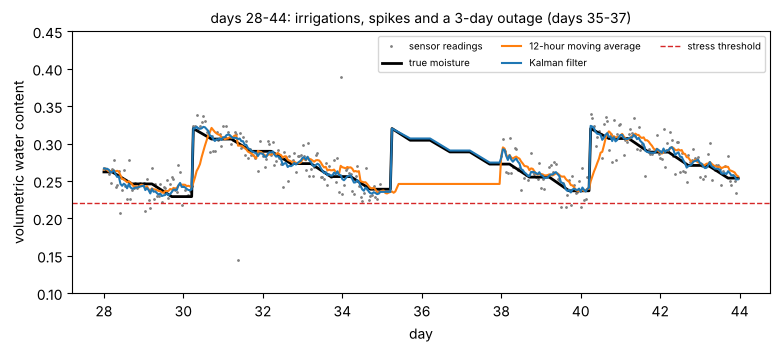

In [2]:
Q, R = 0.003 ** 2, 0.015 ** 2                                       # process and sensor variances (per hour)

def kalman(x, Pv, t, irr, z):
    """One hour: predict with the water balance, then update with reading z (NaN if missing). Returns x, P, innovation."""
    x = min(FC, x + (rain[t] + irr - stress_factor(x) * et0_station[t]) / (1000 * ZR))
    Pv = Pv + Q
    nu = np.nan
    if not np.isnan(z):
        S = Pv + R
        nu = (z - x) / np.sqrt(S)                                  # normalized innovation
        if abs(nu) < 4:                                            # otherwise reject as a probable spike
            K = Pv / S
            x, Pv = x + K * (z - x), (1 - K) * Pv
    return x, Pv, nu

def run_season(policy, offset_correction=False):
    """Simulate 120 days hour by hour. policy(t, state) returns the moisture estimate used at 6:00."""
    s = dict(theta=np.zeros(N), z=np.full(N, np.nan), kf=np.zeros(N), nu=np.full(N, np.nan), irr=np.zeros(N), ks=np.zeros(N),
             offsets=[], last_valid=np.nan, x=0.30, P=0.01 ** 2, offset=0.0, flagged_day=None)
    theta = 0.30
    for t in range(N):
        irr = 0.0
        if hour[t] == 6:
            est = policy(t, s)
            if est is not None and not np.isnan(est) and est < TRIGGER:
                irr = DOSE
        ks = stress_factor(theta)
        theta = min(FC, theta + (rain[t] + irr - ks * et0[t]) / (1000 * ZR))   # water above field capacity drains
        z = np.nan if missing[t] else theta + noise[t] + spikes[t] + drift[t]
        s["theta"][t], s["z"][t], s["irr"][t], s["ks"][t] = theta, z, irr, ks
        if not np.isnan(z):
            s["last_valid"] = z
        s["x"], s["P"], s["nu"][t] = kalman(s["x"], s["P"], t, irr, z - s["offset"] if not np.isnan(z) else z)
        s["kf"][t] = s["x"]
        # field-capacity check: 2 to 12 hours after an irrigation the soil should sit just below field capacity
        t_irr = t - 12
        if t_irr >= 0 and s["irr"][t_irr] > 0:
            window = slice(t_irr + 2, t + 1)
            expected = FC - np.cumsum(et0_station[t_irr + 1:t + 1])[1:] / (1000 * ZR)
            readings = s["z"][window]
            ok = ~np.isnan(readings)
            if ok.sum() >= 5:
                off = np.median(readings[ok] - expected[ok])
                s["offsets"].append((day[t], off))
                if s["flagged_day"] is None and off > 0.03:
                    s["flagged_day"] = day[t]
                if offset_correction and s["flagged_day"] is not None:
                    s["offset"] = off                                  # recalibrate: subtract the latest offset
    return s

truth_policy = lambda t, s: s["theta"][t - 1] if t > 0 else 0.30
ref = run_season(truth_policy)

clean = day < DRIFT_START
latest, last = np.zeros(N), 0.30
for t in range(N):                                                    # carry the last reading through missing hours
    last = ref["z"][t] if not np.isnan(ref["z"][t]) else last
    latest[t] = last
movavg = np.array([np.nanmean(ref["z"][max(0, t - 11):t + 1]) if np.any(~np.isnan(ref["z"][max(0, t - 11):t + 1])) else latest[t]
                   for t in range(N)])
rmse = lambda e, sel: np.sqrt(np.mean((e[sel] - ref["theta"][sel]) ** 2))
outage = (day >= 35) & (day < 38)
for name, e in [("latest reading", latest), ("12-hour moving average", movavg), ("Kalman filter", ref["kf"])]:
    print(f"{name:23s} RMSE days 0-59: {rmse(e, clean):.4f}  | during the 3-day outage: {rmse(e, outage):.4f}")
print(f"spikes rejected by the Kalman filter's 4-sigma gate: {np.sum(spike & clean & (np.abs(ref['nu']) >= 4))} of {np.sum(spike & clean & ~missing)}; "
      f"good readings rejected: {np.sum(~spike & clean & (np.abs(ref['nu']) >= 4))}")

sel = (day >= 28) & (day < 44)
tt = np.arange(N)[sel] / H
plt.figure(figsize=(9, 3.4))
plt.plot(tt, ref["z"][sel], ".", ms=2, color="gray", label="sensor readings")
plt.plot(tt, ref["theta"][sel], "k", lw=2, label="true moisture")
plt.plot(tt, movavg[sel], "C1", label="12-hour moving average")
plt.plot(tt, ref["kf"][sel], "C0", label="Kalman filter")
plt.axhline(TH_STRESS, color="C3", ls="--", lw=1, label="stress threshold")
plt.ylim(0.1, 0.45); plt.xlabel("day"); plt.ylabel("volumetric water content")
plt.title("days 28-44: irrigations, spikes and a 3-day outage (days 35-37)", fontsize=10); plt.legend(fontsize=7, ncol=3, loc="upper right"); plt.show()

### 3. Finding spikes and drift
**Spikes.** A simple **residual rule** flags a reading that is far from the median of the previous 12 readings (more than 4 robust standard deviations, estimated from the median absolute deviation). An **isolation forest** (Liu et al. 2008) is a general-purpose anomaly detector: it isolates points with random splits, and points that are isolated quickly are anomalies. We give it two features per reading, the reading itself and its difference from the recent median, and ask it to flag 1%. Both are scored against the true spikes with precision (how many flags are real spikes) and recall (how many spikes are flagged).

**Drift** is harder: it is slow, so every reading looks normal next to its neighbours. Physics helps. Two to twelve hours after an irrigation the soil should sit just below field capacity, so the median of (reading − expected) in that window estimates the sensor's offset. We flag drift when the offset passes 0.03, twice the noise level.

In [3]:
z = ref["z"]
valid = ~np.isnan(z)
med = np.array([np.nanmedian(z[max(0, t - 12):t]) if np.any(~np.isnan(z[max(0, t - 12):t])) else np.nan for t in range(N)])
resid = z - med
ok = valid & ~np.isnan(med)
mad_sigma = 1.4826 * np.nanmedian(np.abs(resid[ok] - np.nanmedian(resid[ok])))
rule_flag = ok & (np.abs(resid) > 4 * mad_sigma)
features = np.column_stack([z[ok], resid[ok]])
forest = IsolationForest(n_estimators=200, contamination=0.01, random_state=0).fit(features)
forest_flag = np.zeros(N, bool); forest_flag[np.nonzero(ok)[0]] = forest.predict(features) == -1
true_spike = spike & ok
after_event = np.zeros(N, bool)                                       # the 3 hours after a logged irrigation or rain
for t in np.nonzero((ref["irr"] > 0) | (rain > 0))[0]:
    after_event[t:t + 4] = True
for name, f in [("residual rule (4 robust sigma)", rule_flag), ("isolation forest (1%)", forest_flag)]:
    tp = np.sum(f & true_spike)
    print(f"{name:31s}: {f.sum():3d} flags, precision {tp / max(f.sum(), 1):.2f}, recall {tp / true_spike.sum():.2f}; "
          f"false flags {np.sum(f & ~true_spike)}, of which {np.sum(f & ~true_spike & after_event)} within 3 hours of irrigation or rain")

offs = np.array(ref["offsets"])
print(f"field-capacity checks after {len(offs)} irrigations; offsets before day {DRIFT_START}: mean {offs[offs[:, 0] < DRIFT_START, 1].mean():+.4f}, "
      f"largest {np.abs(offs[offs[:, 0] < DRIFT_START, 1]).max():.4f}")
print("checks after day 60 (day: offset): " + ", ".join(f"{int(d)}: {o:+.3f}" for d, o in offs[offs[:, 0] >= DRIFT_START]))
irr_days = np.nonzero(ref["irr"] > 0)[0] // H
print(f"irrigation days after day 60: {[int(d) for d in irr_days[irr_days >= DRIFT_START]]} (a check needs 5 readings in its window)")
print(f"drift flagged on day {ref['flagged_day']} (drift started on day {DRIFT_START}; true drift then {DRIFT_RATE * (ref['flagged_day'] - DRIFT_START):+.3f})")

residual rule (4 robust sigma) :  75 flags, precision 0.32, recall 1.00; false flags 51, of which 42 within 3 hours of irrigation or rain
isolation forest (1%)          :  27 flags, precision 0.81, recall 0.92; false flags 5, of which 3 within 3 hours of irrigation or rain
field-capacity checks after 14 irrigations; offsets before day 60: mean +0.0014, largest 0.0081
checks after day 60 (day: offset): 66: +0.006, 73: +0.021, 81: +0.028, 109: +0.078, 116: +0.085
irrigation days after day 60: [66, 73, 81, 91, 109, 116] (a check needs 5 readings in its window)
drift flagged on day 109 (drift started on day 60; true drift then +0.073)


### 4. From readings to irrigation decisions
Now the decisions feed back: what the farmer does changes the soil, so each strategy gets its own season, with the same weather and the same sensor faults. Four strategies decide at 6:00 from:

1. the **latest raw reading**;
2. the **Kalman filter** (spikes and gaps handled, drift not);
3. the **Kalman filter with recalibration**: once the field-capacity check flags drift, each later reading is corrected by the latest offset estimate;
4. the **true moisture** (impossible in practice; the best this rule can do).

We count irrigation water, the days on which the true moisture spent time below the stress threshold, and the average stress factor $K_s$ (1 means no stress).

strategy                  water (mm)  irrigations  stress days (all / after day 60)  mean Ks  drift flagged
latest raw reading             490          14           18 /  15                0.981   day 88
Kalman filter                  455          13           25 /  22                0.969   day 83
Kalman + recalibration         525          15           10 /   7                0.996   day 83
true moisture                  560          16            0 /   0                1.000   day 109


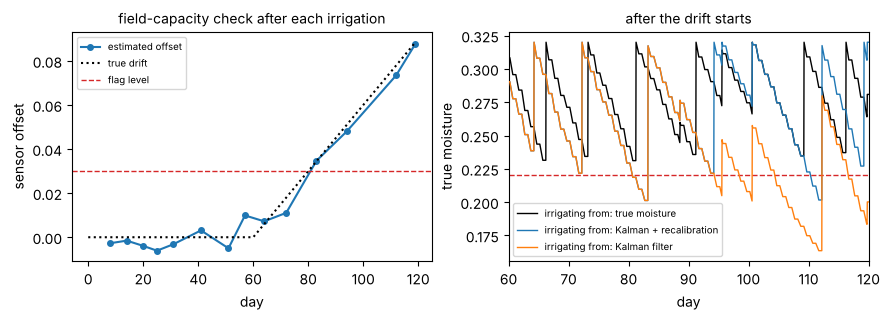

runtime so far 1 s


In [4]:
strategies = {"latest raw reading": (lambda t, s: s["last_valid"], False),
              "Kalman filter": (lambda t, s: s["x"], False),
              "Kalman + recalibration": (lambda t, s: s["x"], True),
              "true moisture": (truth_policy, False)}
seasons = {}
print("strategy                  water (mm)  irrigations  stress days (all / after day 60)  mean Ks  drift flagged")
for name, (pol, corr) in strategies.items():
    s = run_season(pol, offset_correction=corr)
    seasons[name] = s
    stressed = (s["theta"].reshape(DAYS, H) < TH_STRESS).any(axis=1)
    print(f"{name:25s} {s['irr'].sum():8.0f}  {int((s['irr'] > 0).sum()):10d}          {stressed.sum():3d} / {stressed[DRIFT_START:].sum():3d}"
          f"                {s['ks'].mean():.3f}   {'day ' + str(s['flagged_day']) if s['flagged_day'] is not None else 'no'}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
o = np.array(seasons["Kalman + recalibration"]["offsets"])
ax[0].plot(o[:, 0], o[:, 1], "o-", ms=4, label="estimated offset")
ax[0].plot(np.arange(DAYS), np.where(np.arange(DAYS) >= DRIFT_START, DRIFT_RATE * (np.arange(DAYS) - DRIFT_START), 0), "k:", label="true drift")
ax[0].axhline(0.03, color="C3", ls="--", lw=1, label="flag level")
ax[0].set_xlabel("day"); ax[0].set_ylabel("sensor offset"); ax[0].set_title("field-capacity check after each irrigation", fontsize=10)
ax[0].legend(fontsize=7)
for name, c, zo in [("true moisture", "k", 1), ("Kalman + recalibration", "C0", 2), ("Kalman filter", "C1", 3)]:
    ax[1].plot(np.arange(N) / H, seasons[name]["theta"], color=c, lw=1, label=f"irrigating from: {name}", zorder=zo)
ax[1].axhline(TH_STRESS, color="C3", ls="--", lw=1)
ax[1].set_xlim(60, 120); ax[1].set_xlabel("day"); ax[1].set_ylabel("true moisture"); ax[1].set_title("after the drift starts", fontsize=10)
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"runtime so far {time.time() - t_start:.0f} s")

### 5. Advice the farmer can use
A decision is only useful if it reaches the farmer in a form they can act on. A short message in Bangla, sent by SMS or read aloud by a voice service (Course 12 sessions 2 and 9 cover Bangla speech recognition and text-to-speech), can carry the decision and its reason. The cell builds the morning message from the filter's estimate and the sensor's health.

In [5]:
def morning_message(theta_est, flagged):
    need = max(0.0, (FC - theta_est) * 1000 * ZR)                      # mm to refill to field capacity
    if flagged:
        return "সেন্সর ঠিকমতো কাজ করছে না, মাঠের মাটি হাতে পরীক্ষা করুন। (The sensor needs checking: test the soil by hand.)"
    if theta_est < TRIGGER:
        return f"আজ সেচ দিন: প্রায় {need:.0f} মিমি পানি। (Irrigate today: about {need:.0f} mm.)"
    return "আজ সেচের দরকার নেই। (No irrigation needed today.)"

s = seasons["Kalman + recalibration"]
for d in [20, 45, 75]:
    t = d * H + 6
    print(f"day {d}: estimate {s['kf'][t - 1]:.3f}, true {s['theta'][t - 1]:.3f} -> {morning_message(s['kf'][t - 1], False)}")
print(f"on the day drift was flagged ({s['flagged_day']}): {morning_message(0.3, True)}")

day 20: estimate 0.226, true 0.228 -> আজ সেচ দিন: প্রায় 28 মিমি পানি। (Irrigate today: about 28 mm.)
day 45: estimate 0.260, true 0.252 -> আজ সেচের দরকার নেই। (No irrigation needed today.)
day 75: estimate 0.307, true 0.284 -> আজ সেচের দরকার নেই। (No irrigation needed today.)
on the day drift was flagged (83): সেন্সর ঠিকমতো কাজ করছে না, মাঠের মাটি হাতে পরীক্ষা করুন। (The sensor needs checking: test the soil by hand.)


### 6. Real data (NOT RUN here)
Many low-cost sensor projects send readings over the mobile network or LoRaWAN to a cloud service. ThingSpeak, for example, serves a channel's readings as CSV over a web address. Put your own channel number (and read key, for a private channel) in the cell, then run sections 2–4 on your readings.

In [ ]:
# NOT RUN: needs internet access and a ThingSpeak channel of your own (the channel number below is a placeholder)
import pandas as pd

CHANNEL = 0000000                                                  # replace with your channel number
url = f"https://api.thingspeak.com/channels/{CHANNEL}/feeds.csv?results=8000"
df = pd.read_csv(url, parse_dates=["created_at"])
soil = df.set_index("created_at")["field1"].astype(float)          # assume field 1 holds volumetric water content
hourly = soil.resample("1h").mean()                                # one value per hour; NaN where nothing arrived
print(f"{len(soil)} readings, {hourly.isna().mean():.1%} of hours missing")
print(hourly.describe())

### 7. Exercises

In [6]:
# TODO: tune the Kalman filter. Rerun the reference season (truth_policy) with process standard deviations of 0.001,
# 0.003 and 0.01 per hour (set the global Q before each run) and report the RMSE on days 0-59 and during the outage.
# What goes wrong when Q is too small, and when it is too large?
def tune_q(stds=(0.001, 0.003, 0.01)):
    return None          # replace with your code; return {std: (rmse_clean, rmse_outage)}

r = tune_q()
print("not done yet" if r is None else r)

not done yet


In [7]:
# TODO: a CUSUM drift detector. A healthy filter's normalized innovations ref["nu"] have mean 0. Compute
# S_t = max(0, S_{t-1} + nu_t - k) over the valid hours with k = 0.25, and flag drift when S_t > h = 20.
# On which day does it flag? Does it ever flag before day 60? Compare with the field-capacity check.
def cusum_day(nu, k=0.25, h=20.0):
    return None          # replace with your code; return the day of the first flag (or None)

r = cusum_day(ref["nu"])
print("not done yet" if r is None else f"CUSUM flags drift on day {r}")

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds.)

1. **A filter that knows the water balance beats a window.** On days 0–59 the RMSE against the true moisture was 0.0229 for the latest reading, 0.0179 for the 12-hour moving average and 0.0047 for the Kalman filter. During the 3-day outage it was 0.0479, 0.0486 and 0.0021: the Kalman filter kept predicting from the logged irrigation and the weather, while the others froze at the last reading. Its 4-sigma gate rejected all 13 spikes seen in days 0–59 and no good reading. The moving average lagged hours behind every irrigation (first figure).
2. **Spike detectors mistake real jumps for faults.** The residual rule caught every spike (recall 1.00) with precision only 0.32: 42 of its 51 false flags came within 3 hours of an irrigation or rain, real jumps it knew nothing about. The isolation forest flagged 27 readings, with precision 0.81 and recall 0.92. Giving a detector the irrigation log would remove most of these false alarms.
3. **Drift is invisible to spike detectors and to the filter, and the physical check is slow.** Before day 60 the field-capacity offsets averaged +0.0014 (largest 0.0081). Afterwards they grew: +0.006 on day 66, +0.021, +0.028, and +0.078 on day 109, when the reference season first flagged drift. That was late because the check runs only after irrigations: the day-91 check fell in the radio outage and the next irrigation came on day 109.
4. **Against our expectation, removing noise without fixing drift made decisions worse.** Deciding from the Kalman filter alone, the true moisture fell below the stress threshold on 25 days (22 after day 60), against 18 for the latest raw reading, and it used less water (455 against 490 mm) because the drifting sensor said the soil was wetter. The raw readings probably did better by accident, as their noise sometimes dipped below the trigger early. With recalibration (drift flagged on day 83 in that season) stress days fell to 10, 7 of them after day 60, and the mean stress factor rose to 0.996, using 525 mm. Irrigating from the true moisture used 560 mm with no stress days: here the best decisions used the most water, not the least.
5. **A decision needs a message.** On day 20 the estimate (0.226, true 0.228) gave "irrigate about 28 mm"; when drift was flagged, the message asked the farmer to check the soil by hand rather than trust the sensor.